In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
def ssa_hyperbolic(x0,tau,beta,gamma,sigma):
    y=np.zeros(max_size)               #plasmid count count; y[0]=x[0], y[1]=0, y[i] = number of cluster of size i 
    y[0]=x0
    x=[x0]
    t_x = [0]
    t_y=0             #reaction time 
    y_tot = x0
    while t_y<tau:
        c_idx = np.where(y>0)[0]                                  #indices of species with non-zero state
        N= len(c_idx)
        num_reax = N+1+int(((N-1)**2-N+1)/2)+2*(N-1)              #possible number of reactions given the system state 
        a =np.zeros(num_reax)                                     #reaction hazards 
        v=np.zeros([num_reax,max_size])                           #reaction vectors
        
        a[0]=(k_tr*y_tot)/(1+K*y_tot/(s0*n))**n
        v[0,0] = 1
        a[1] = 0.5*beta*y[0]*(y[0]-1)
        v[1,0] = -2
        v[1,2] = 1

        if N>1:
            species_idx =np.zeros([2,num_reax])
            count=1
            for i in np.arange(1,N):   #plasmid recruitment
                count+=1
                a[count] = beta*y[0]*y[c_idx[i]]
                species_idx[:,count] = np.array([c_idx[i],0])
            rec_count=count
                
            for i in np.arange(1,N):   #cluster combination
                for j in np.arange(i,N):
                    count+=1
                    if i==j:
                        a[count] = 0.5*gamma*y[c_idx[i]]*(y[c_idx[j]]-1)
                    else:
                        a[count] = gamma*y[c_idx[i]]*y[c_idx[j]]
                    species_idx[:,count] = [c_idx[i],c_idx[j]]
            cluster_count = count
            
            for i in np.arange(1,N): #plasmid shedding
                count+=1
                a[count] = sigma*y[c_idx[i]]*c_idx[i]
                species_idx[:,count] = np.array([c_idx[i],0])
                    
            for i in range(len(a)): #reaction vectors
                if i==0:                         #plasmid replication
                    v[i,0] = 1
                elif i==1:                       #plasmid duplex formation
                    v[i,0] = -2
                    v[i,2] = 1
                elif (2<=i and i<=rec_count):    #plasmid recruitment to a cluster
                    v[i,0] = -1
                    v[i,int(species_idx[0,i])] = -1
                    v[i,int(species_idx[0,i])+1] = 1
                elif (i>rec_count and i<=cluster_count):   #cluster combination
                    if (int(species_idx[0,i])==int(species_idx[1,i])):
                        v[i,int(species_idx[0,i])] = -2
                    else:
                        v[i,int(species_idx[0,i])] = -1
                        v[i,int(species_idx[1,i])] = -1
                    v[i,int(np.sum(species_idx[:,i]))] = 1
                else:                            #plasmid shedding         
                    v[i,0] = 1
                    v[i,int(species_idx[0,i])] = -1
                    v[i,int(species_idx[0,i])-1] = 1   
        
        sum_a=np.sum(a)
        cumsum_a=np.cumsum(a,axis=0)
        epsilon=np.random.uniform(0,1,2)
        j=np.min(np.where(epsilon[0]*sum_a<cumsum_a)) 
        t_f=(np.log(1/epsilon[1]))/sum_a
          
        if t_y+t_f<=tau:  
            t_y+=t_f 
            y=y+v[j,:]
            y[0]+=y[1]
            y[1]=0
            y_tot =y[0]
            for i in np.arange(1,max_size):
                y_tot +=i*y[i] 
            if j==0:
                x= np.append(x,y_tot)
                t_x =np.append(t_x,[t_y])
        else:
            t_y=tau
            x=np.append(x,x[-1])
            t_x =np.append(t_x,[t_y])      
    return y,x,t_y,t_x

def single_lineage(x0,gen,tau,cluster,thresh,beta,gamma,sigma):
    x=[x0]
    t=[0]
    cluster_num = np.zeros(gen)
    ratio = np.zeros([gen,2])  #ratio = [inheritance,parent]
    z=np.zeros(max_size)   #keep track of n-cluster numbers
    count=0
    for i in range(gen):
        if i%100==0:
            print(i)
        if x0>0:
            count+=1
            yy,xx,tty,ttx=ssa_hyperbolic(x0,tau,beta,gamma,sigma)
            if cluster==False:
                x0=np.random.binomial(xx[-1],0.5)
            else:
                x=np.append(x,xx)
                t=np.append(t,t[-1]+ttx)
                clusters = yy[:np.max(np.where(yy>0))+1]
                clusters[1] = clusters[0]
                x0=0
                while x0==0:  ##### here just to have continuous simulation
                    for k in np.arange(1,len(clusters)):    #plasmid segregation; binomial
                        seg_count = np.random.binomial(int(clusters[k]),0.5)
                        x0+=k*seg_count   
            ratio[i,:]=[xx[-1],x0/xx[-1]]
            z+=yy
        cluster_num[i] = np.sum(yy[thresh:]) 
    return x,t,ratio[:count,:],cluster_num[:count],z


def plot_stairs(x,t):
    l=len(t)
    for i in range(l-1):
        vec_t=[t[i],t[i+1]]
        vec_x=[x[i],x[i]]
        axes[0].plot(vec_t,vec_x,color='k')
        if x[i]-x[i+1]>0:
            axes[0].vlines(t[i+1],x[i],x[i+1],color='red')
        else:
            axes[0].vlines(t[i+1],x[i],x[i+1],color='k')
    axes[0].set_ylim([0,max(x)+1])
    axes[0].set_xlim([0,gen*tau])
    axes[0].set_xlabel('Time (min)')
    axes[0].set_ylabel('Plasmid copy number')
    return None

def plot_stairs_multiple(x,t,k):
    l=len(t)
    for i in range(l-1):
        vec_t=[t[i],t[i+1]]
        vec_x=[x[i],x[i]]
        axes[k].plot(vec_t,vec_x,color='k')
        if x[i]-x[i+1]>0:
            axes[k].vlines(t[i+1],x[i],x[i+1],color='red')
        else:
            axes[k].vlines(t[i+1],x[i],x[i+1],color='k')
    axes[k].set_ylim([0,100])
    axes[k].set_xlim([0,gen*tau])
    axes[k].set_xlabel('time')
    axes[k].hlines(41,0,gen*tau,color='grey')
    if k>0:
        axes[k].set_yticklabels([])
    return None

In [6]:
tau = 60
k_tr = 2.73
K = 9.007936508
s0 = 13.58595
n = 2.5
x0=20
max_size=200
beta = 0.1 #plasmid recruitment rate constant
gamma = 1*beta #plasmid combination rate constant
sigma= 1*beta  #plasmid dissociation rate constant

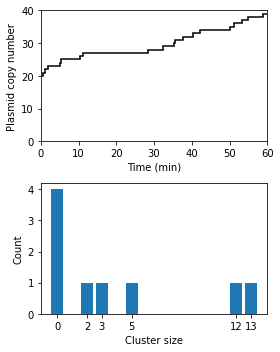

In [8]:
gen=1
f,axes = plt.subplots(2,1,figsize=(4,5))
y,x,t_y,t_x = ssa_hyperbolic(x0,tau,beta,gamma,sigma)
plot_stairs(x,t_x)
axes[1].bar(range(np.max(np.where(y>0))+1),y[:np.max(np.where(y>0))+1])
axes[1].set_xticks(np.where(y>0)[0])
axes[1].set_xlabel('Cluster size')
axes[1].set_ylabel('Count')
plt.tight_layout()
plt.show()

What is a cluster? What is the threshold size for a group to be called a cluster?
We can keep track of the distribution of number of clusters in a lineage.



0
100
200
300
400
500
600
700
800
900


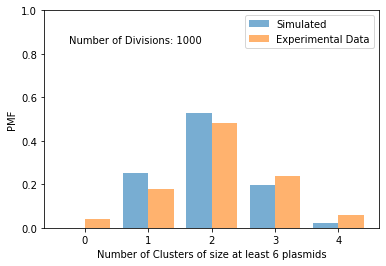

[0.    0.254 0.527 0.196 0.023]


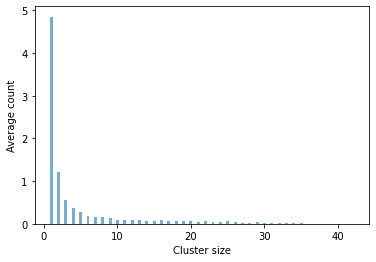

42.172


In [9]:
c_thresh = 6
cluster = True
gen=1000
x,t,ratio,c_num,z=single_lineage(x0,gen,tau,cluster,c_thresh,beta,gamma,sigma)
heights = np.bincount(c_num.astype(int))/len(c_num)
bars = plt.bar(np.arange(len(heights))-0.2,heights,width=0.4,color='C0',alpha=0.6,label='Simulated') 
#for bar in bars:
#    yval = bar.get_height()
#    plt.text(bar.get_x(), yval + .005, '%1.3f' %(yval))
plt.text(-0.25,0.85,'Number of Divisions: %d' %len(c_num))
plt.bar(np.arange(5)+0.2,[0.04,0.18,0.48,0.24,0.06],width=0.4,color='C1',alpha=0.6,label='Experimental Data')
plt.ylim([0,1])
plt.xticks(range(len(heights)))
plt.xlabel('Number of Clusters of size at least %d plasmids' %(c_thresh))
plt.ylabel('PMF')
plt.legend()
plt.show()
print(heights)

f = plt.figure()
last = np.max(np.where(z>0)[0])
z[1]=z[0]
bars = plt.bar(np.arange(1,last+1),z[1:last+1]/len(c_num),width=0.4,color='C0',alpha=0.6) 
plt.xlabel('Cluster size')
plt.ylabel('Average count')
plt.xlim([0,40])
plt.ylim([0,7])
plt.show()
print(np.dot(np.arange(1,last+1),(z[1:last+1]/len(c_num))))

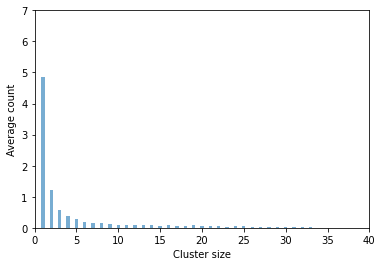

42.172


In [10]:
f = plt.figure()
last = np.max(np.where(z>0)[0])
z[1]=z[0]
bars = plt.bar(np.arange(1,last+1),z[1:last+1]/len(c_num),width=0.4,color='C0',alpha=0.6) 
plt.xlabel('Cluster size')
plt.ylabel('Average count')
plt.xlim([0,40])
plt.ylim([0,7])
plt.show()
print(np.dot(np.arange(1,last+1),(z[1:last+1]/len(c_num))))

In [ ]:
repeats = 5
gen=5
cluster=True
f,axes = plt.subplots(1,repeats,figsize=(10,3))
for i in range(repeats):
    x,t,_,__=single_lineage(x0,gen,tau,cluster,0)
    plot_stairs_multiple(x,t,i)
axes[0].set_ylabel('Plasmid copy number')    
plt.tight_layout()

In [ ]:
cluster=[False,True]
gen=1000
f = plt.figure()
for j in range(2):
    x,t,ratio1,_=single_lineage(x0,gen,tau,cluster[j],0)
    ratio2 = np.zeros([len(ratio1),2])
    for i in range(len(ratio1)):
        ratio2[i,:]=[ratio1[i,0],1-ratio1[i,1]] 
    ratio = np.append(ratio1,ratio2,axis=0)
    sns.jointplot(ratio[:,0],ratio[:,1])
    if cluster[j]==True:
        ratio_c = ratio
    else:
        ratio_uc = ratio

In [ ]:
f,axes=plt.subplots(2,1)
sns.kdeplot(ratio_uc[:,1],label='Binomial',shade=True,ax=axes[0],color='r')
sns.kdeplot(ratio_c[:,1],label='Clustered',shade=True,ax=axes[0],color='C0')
axes[0].set_xlabel(r'$N_d/N_p$',fontsize=14)
axes[0].text(-0.1,4,'Number of Divisions: %d' %(int(len(ratio_c)/2)), color='C0')
axes[0].set_ylim([0,5])

sns.kdeplot(ratio_uc[:,0],label='Binomial',shade=True,ax=axes[1],color='r')
sns.kdeplot(ratio_c[:,0],label='Clustered',shade=True,ax=axes[1],color='C0')
axes[1].set_xlabel(r'$N_p$',fontsize=14)
plt.tight_layout()